# **Лабораторна робота 6**
**Тема:** Асоціативні структури даних: словники та множини.

**Мета:** Опанувати практичні навички проектування та застосування асоціативних структур даних і хеш-таблиць мовою Python. Навчитися реалізовувати базові операції створення, модифікації, безпечного доступу та видалення записів у словниках (dict), застосовувати спеціалізовані методи get(), setdefault(), pop(), update(), а також будувати оптимізовані інвертовані індекси за допомогою генераторів словників (Dict Comprehensions). Опанувати частотний аналіз системних подій із використанням класу collections.Counter та навчитися виконувати теоретико-множинні операції над змінюваними (set) і незмінними (frozenset) множинами для розв'язання задач інвентаризації мережевих ресурсів, аудиту прав доступу користувачів та розрахунку метрик схожості системних конфігурацій.


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

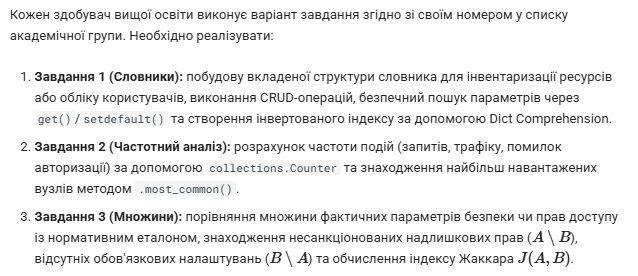

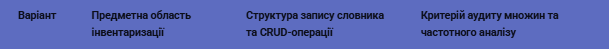
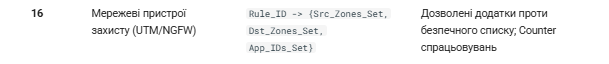

**ЗАВДАННЯ 1. Інвентаризація правил UTM/NGFW, CRUD-операції та інвертований індекс**

In [1]:
def manage_ngfw_policies() -> dict[str, dict[str, set[str]]]:
    # Базова структура інвентаризації: Rule_ID -> {Src_Zones_Set, Dst_Zones_Set, App_IDs_Set}
    firewall_rules: dict[str, dict[str, set[str]]] = {
        "FW-101": {
            "Src_Zones_Set": {"LAN_CORP", "VPN_USERS"},
            "Dst_Zones_Set": {"DMZ_WEB", "WAN_INET"},
            "App_IDs_Set": {"ssl", "web-browsing", "dns"}
        },
        "FW-102": {
            "Src_Zones_Set": {"LAN_DEV"},
            "Dst_Zones_Set": {"CLOUD_PROD"},
            "App_IDs_Set": {"ssh", "git-base", "docker-registry"}
        },
        "FW-103": {
            "Src_Zones_Set": {"GUEST_WIFI"},
            "Dst_Zones_Set": {"WAN_INET"},
            "App_IDs_Set": {"web-browsing", "dns", "quic"}
        },
        "FW-104": {
            "Src_Zones_Set": {"LAN_ADMIN"},
            "Dst_Zones_Set": {"MGMT_NET"},
            "App_IDs_Set": {"ssh", "snmpv3", "syslog-tls", "telnet"}
        }
    }

    # 1. CREATE: додавання нового правила безпеки
    firewall_rules["FW-105"] = {
        "Src_Zones_Set": {"LAN_CORP"},
        "Dst_Zones_Set": {"DB_CLUSTER"},
        "App_IDs_Set": {"postgresql", "kerberos"}
    }

    # 2. READ (безпечний пошук через get() та ініціалізація через setdefault())
    missing_rule = firewall_rules.get(
        "FW-999",
        {"Src_Zones_Set": set(), "Dst_Zones_Set": set(), "App_IDs_Set": set()}
    )
    _ = len(missing_rule["App_IDs_Set"])

    firewall_rules.setdefault(
        "FW-106",
        {
            "Src_Zones_Set": {"IOT_SENSORS"},
            "Dst_Zones_Set": {"MQTT_BROKER"},
            "App_IDs_Set": {"mqtt-tls"}
        }
    )

    # 3. UPDATE: оновлення параметрів правил через update()
    firewall_rules["FW-101"]["App_IDs_Set"].update({"ntp", "ocsp"})
    firewall_rules["FW-104"].update({
        "Dst_Zones_Set": {"MGMT_NET", "BACKUP_SAN"}
    })

    # 4. DELETE: видалення застарілого правила FW-103 за допомогою pop()
    removed_rule = firewall_rules.pop("FW-103", None)

    print("=" * 94)
    print(f"{'ІНВЕНТАРИЗАЦІЯ ПРАВИЛ БЕЗПЕКИ UTM / NGFW (ПІСЛЯ CRUD-ОПЕРАЦІЙ)':^94}")
    print("=" * 94)
    print(
        f"{'Rule ID':<10} | "
        f"{'Source Zones':<22} | "
        f"{'Destination Zones':<22} | "
        f"{'Allowed App-IDs':<30}"
    )
    print("-" * 94)

    for rule_id, cfg in firewall_rules.items():
        src_str = ", ".join(sorted(cfg["Src_Zones_Set"]))
        dst_str = ", ".join(sorted(cfg["Dst_Zones_Set"]))
        app_str = ", ".join(sorted(cfg["App_IDs_Set"]))
        print(f"{rule_id:<10} | {src_str:<22} | {dst_str:<22} | {app_str:<30}")

    print("-" * 94)
    print(
        f"Видалене правило (pop): {'FW-103' if removed_rule else 'Відсутнє'} | "
        f"Активних правил: {len(firewall_rules)}"
    )
    print("=" * 94)

    # 5. Інвертований індекс: App_ID -> frozenset(Rule_IDs) за допомогою Dict Comprehension
    all_apps = {app for cfg in firewall_rules.values() for app in cfg["App_IDs_Set"]}
    inverted_app_index: dict[str, frozenset[str]] = {
        app: frozenset(
            rule_id for rule_id, cfg in firewall_rules.items() if app in cfg["App_IDs_Set"]
        )
        for app in sorted(all_apps)
    }

    print(f"\n{'ІНВЕРТОВАНИЙ ІНДЕКС ДОДАТКІВ (App-ID -> Правила NGFW)':^68}")
    print("-" * 68)
    print(f"{'App-ID':<20} | {'К-сть правил':>12} | {'Ідентифікатори правил (frozenset)':<30}")
    print("-" * 68)
    for app, rules_fset in inverted_app_index.items():
        print(f"{app:<20} | {len(rules_fset):>12d} | {', '.join(sorted(rules_fset)):<30}")
    print("-" * 68)

    return firewall_rules


rules_db = manage_ngfw_policies()

                ІНВЕНТАРИЗАЦІЯ ПРАВИЛ БЕЗПЕКИ UTM / NGFW (ПІСЛЯ CRUD-ОПЕРАЦІЙ)                
Rule ID    | Source Zones           | Destination Zones      | Allowed App-IDs               
----------------------------------------------------------------------------------------------
FW-101     | LAN_CORP, VPN_USERS    | DMZ_WEB, WAN_INET      | dns, ntp, ocsp, ssl, web-browsing
FW-102     | LAN_DEV                | CLOUD_PROD             | docker-registry, git-base, ssh
FW-104     | LAN_ADMIN              | BACKUP_SAN, MGMT_NET   | snmpv3, ssh, syslog-tls, telnet
FW-105     | LAN_CORP               | DB_CLUSTER             | kerberos, postgresql          
FW-106     | IOT_SENSORS            | MQTT_BROKER            | mqtt-tls                      
----------------------------------------------------------------------------------------------
Видалене правило (pop): FW-103 | Активних правил: 5

       ІНВЕРТОВАНИЙ ІНДЕКС ДОДАТКІВ (App-ID -> Правила NGFW)        
-------------------------

**ЗАВДАННЯ 2. Частотний аналіз спрацьовувань правил NGFW (collections.Counter)**

In [2]:
from collections import Counter


def analyze_rule_hits(hit_events: list[str], valid_rules: set[str]) -> Counter:
    hits_counter = Counter(hit_events)
    total_hits = sum(hits_counter.values())

    print(f"{'ЧАСТОТНИЙ АНАЛІЗ СПРАЦЬОВУВАНЬ ПРАВИЛ (collections.Counter)':^76}")
    print("=" * 76)
    print(
        f"{'Ранг':<6} | "
        f"{'Rule ID':<12} | "
        f"{'Спрацьовувань':>15} | "
        f"{'Частка (%)':>12} | "
        f"{'Статус в базі':<18}"
    )
    print("-" * 76)

    for rank, (rule_id, count) in enumerate(hits_counter.most_common(), start=1):
        share_pct = (count / total_hits * 100.0) if total_hits > 0 else 0.0
        status = "Активне" if rule_id in valid_rules else "Архівне / Невідоме"
        print(f"{rank:<6d} | {rule_id:<12} | {count:>15d} | {share_pct:>11.2f}% | {status:<18}")

    print("-" * 76)
    top_3 = ", ".join(f"{r} ({c})" for r, c in hits_counter.most_common(3))
    print(f"Усього подій: {total_hits} | Топ-3 найбільш навантажені правила: {top_3}")
    print("=" * 76)

    return hits_counter


firewall_hit_stream = [
    "FW-101", "FW-101", "FW-102", "FW-101", "FW-105",
    "FW-104", "FW-101", "FW-106", "FW-102", "FW-101",
    "FW-105", "FW-105", "FW-103", "FW-101", "FW-102",
    "FW-106", "FW-101", "FW-104", "FW-105", "FW-101"
]

rule_hits_stats = analyze_rule_hits(firewall_hit_stream, set(rules_db.keys()))

        ЧАСТОТНИЙ АНАЛІЗ СПРАЦЬОВУВАНЬ ПРАВИЛ (collections.Counter)         
Ранг   | Rule ID      |   Спрацьовувань |   Частка (%) | Статус в базі     
----------------------------------------------------------------------------
1      | FW-101       |               8 |       40.00% | Активне           
2      | FW-105       |               4 |       20.00% | Активне           
3      | FW-102       |               3 |       15.00% | Активне           
4      | FW-104       |               2 |       10.00% | Активне           
5      | FW-106       |               2 |       10.00% | Активне           
6      | FW-103       |               1 |        5.00% | Архівне / Невідоме
----------------------------------------------------------------------------
Усього подій: 20 | Топ-3 найбільш навантажені правила: FW-101 (8), FW-105 (4), FW-102 (3)


**ЗАВДАННЯ 3. Теоретико-множинний аудит App-ID та індекс Жаккара J(A, B)**

In [3]:
def audit_allowed_applications(
    firewall_rules: dict[str, dict[str, set[str]]],
    baseline_safe_apps: frozenset[str]
) -> float:
    # A — множина всіх фактично дозволених додатків на UTM/NGFW
    actual_allowed_apps: set[str] = set()
    for cfg in firewall_rules.values():
        actual_allowed_apps.update(cfg["App_IDs_Set"])

    # B — нормативний еталон безпечного списку додатків (frozenset)
    B = baseline_safe_apps
    A = actual_allowed_apps

    unauthorized_apps = A - B          # A \ B: несанкціоновані надлишкові додатки
    missing_mandatory_apps = B - A     # B \ A: відсутні обов'язкові безпечні додатки
    compliant_apps = A & B             # A ∩ B: відповідні еталону додатки
    union_apps = A | B                 # A ∪ B: об'єднання множин

    jaccard_index = len(compliant_apps) / len(union_apps) if union_apps else 1.0

    print(f"{'АУДИТ ДОЗВОЛЕНИХ ДОДАТКІВ ПРОТИ БЕЗПЕЧНОГО СПИСКУ (BASELINE)':^82}")
    print("=" * 82)
    print(f"Фактично дозволені (|A| = {len(A)}) : {', '.join(sorted(A))}")
    print(f"Безпечний еталон   (|B| = {len(B)}) : {', '.join(sorted(B))}")
    print("-" * 82)
    print(f"Відповідають еталону (A ∩ B)  : {', '.join(sorted(compliant_apps)) or 'Немає'}")
    print(f"Надлишкові / ризикові (A \\ B) : {', '.join(sorted(unauthorized_apps)) or 'Немає'}")
    print(f"Відсутні з еталону    (B \\ A) : {', '.join(sorted(missing_mandatory_apps)) or 'Немає'}")
    print("-" * 82)
    print(
        f"Коефіцієнт подібності Жаккара J(A, B) = |A ∩ B| / |A ∪ B| = "
        f"{len(compliant_apps)}/{len(union_apps)} = {jaccard_index:.4f} ({jaccard_index * 100:.2f}%)"
    )
    print("=" * 82)

    return jaccard_index


approved_baseline = frozenset({
    "ssl", "web-browsing", "dns", "ssh", "git-base",
    "ntp", "ocsp", "kerberos", "syslog-tls", "ldaps"
})

j_score = audit_allowed_applications(rules_db, approved_baseline)

           АУДИТ ДОЗВОЛЕНИХ ДОДАТКІВ ПРОТИ БЕЗПЕЧНОГО СПИСКУ (BASELINE)           
Фактично дозволені (|A| = 14) : dns, docker-registry, git-base, kerberos, mqtt-tls, ntp, ocsp, postgresql, snmpv3, ssh, ssl, syslog-tls, telnet, web-browsing
Безпечний еталон   (|B| = 10) : dns, git-base, kerberos, ldaps, ntp, ocsp, ssh, ssl, syslog-tls, web-browsing
----------------------------------------------------------------------------------
Відповідають еталону (A ∩ B)  : dns, git-base, kerberos, ntp, ocsp, ssh, ssl, syslog-tls, web-browsing
Надлишкові / ризикові (A \ B) : docker-registry, mqtt-tls, postgresql, snmpv3, telnet
Відсутні з еталону    (B \ A) : ldaps
----------------------------------------------------------------------------------
Коефіцієнт подібності Жаккара J(A, B) = |A ∩ B| / |A ∪ B| = 9/15 = 0.6000 (60.00%)


**Висновки**

1. **Швидкодія та константна складність $O(1)$ асоціативних масивів:** Використання словників (`dict`), `collections.Counter` та множин (`set`, `frozenset`), побудованих на базі хеш-таблиць, забезпечує амортизовану константну часову складність $O(1)$ для операцій пошуку, вставки, оновлення та перевірки належності елемента (`in`). Це критично при обробці конфігурацій мережевих пристроїв UTM/NGFW та високонавантажених журналів подій, оскільки час звернення до правила чи підрахунку спрацьовувань практично не залежить від загального розміру набору даних.
2. **Переваги генераторів словників (Dict Comprehensions):** Dict Comprehensions дозволяють декларативно, компактно й у межах одного проходу формувати нові асоціативні структури та інвертовані індекси (`App_ID -> frozenset(Rule_IDs)`). Порівняно з імперативними циклами зі створенням порожнього словника та багаторядковою ініціалізацією, вони підвищують читабельність коду, зменшують кількість звернень до об'єкта на рівні байт-коду та спрощують трансформацію даних.
3. **Роль множин у задачах аудиту кібербезпеки:** Множини (`set` і незмінні `frozenset`) забезпечують відсутність дублікатів та швидкі теоретико-множинні операції ($O(|A| + |B|)$ у середньому випадку) для зіставлення фактичних налаштувань із нормативним еталоном безпеки. Перетин ($A \cap B$) виділяє дозволені базові сервіси, різниця ($A \setminus B$) виявляє несанкціоновані або потенційно небезпечні протоколи/додатки (наприклад, `telnet`), різниця ($B \setminus A$) — відсутні обов'язкові елементи еталону, а коефіцієнт Жаккара $J(A, B) = rac{|A \cap B|}{|A \cup B|}$ дає кількісну метрику відповідності конфігурації вимогам безпеки.

**Контрольні питання**

1. Як влаштована компактна хеш-таблиця (Compact Dict) в інтерпретаторі CPython? Яким чином розділення на розріджену таблицю indices та щільний масив entries гарантує збереження порядку вставки елементів?

У CPython (версії 3.6+) словник розділено на два масиви: розріджений масив індексів indices (розміром $2^k$, заповнений маркерами порожніх слотів або індексами) та щільний послідовний масив записів entries, де зберігаються кортежі (hash, key, value). Під час вставки обчислений хеш визначає слот у indices, куди записується номер наступної вільної комірки масиву entries, а сам запис додається строго в кінець entries. Під час ітерації інтерпретатор послідовно проходить по масиву entries, що гарантує збереження порядку вставки та зменшує витрати пам'яті.

2. Сформулюйте контракт хешованості об'єкта (hashability). Чому об'єкти типу set та list не можуть бути елементами множини або ключами словника, а об'єкти типу frozenset та tuple — можуть?

Об'єкт є хешованим, якщо він реалізує метод __hash__() (повертає стале ціле число протягом усього життєвого циклу) та __eq__() (для розв'язання колізій), причому виконується інваріант: a == b => hash(a) == hash(b). Змінювані структури (list, set) не можуть бути ключами словника чи елементами множини, бо зміна їхнього вмісту змінила б хеш і зробила б пошук у бакеті неможливим. Незмінні типи (frozenset, а також tuple, якщо всі його елементи хешовані) мають фіксований хеш, тому відповідають контракту хешованості.

3. Чим семантично відрізняється робота методу dict.get(key, default) від методу dict.setdefault(key, default)? У яких інженерних алгоритмах застосування setdefault() є найбільш доцільним?

Метод dict.get(key, default) лише читає значення за ключем і в разі його відсутності повертає default без модифікації словника. Метод dict.setdefault(key, default), якщо ключ відсутній, вставляє пару key: default безпосередньо в словник і повертає це значення. Найдоцільніше застосовувати setdefault() під час однопрохідного групування елементів або побудови інвертованих індексів та списків суміжності без попередньої перевірки наявності ключа.

4. Розкрийте математичний та інженерний зміст коефіцієнта подібності Жаккара. Як за допомогою операцій над множинами intersection та union розрахувати ступінь відповідності конфігурації еталону?

Коефіцієнт Жаккара визначається як відношення потужності перетину двох множин до потужності їхнього об'єднання: $J(A, B) = \frac{|A \cap B|}{|A \cup B|}$, $0 \le J(A, B) \le 1$. В інженерному аудиті конфігурацій він кількісно оцінює ступінь відповідності фактичних налаштувань ($A$) нормативному еталону ($B$): значення 1.0 означає повну відповідність. У Python обчислюється через len(A.intersection(B)) / len(A.union(B)).

5. Опишіть алгоритмічні переваги класу collections.Counter над звичайним словником dict при підрахунку частоти подій у високонавантажених потоках логів.

Counter є підкласом dict для частотного аналізу: при зверненні до відсутнього ключа він повертає 0 замість KeyError, має вбудований метод .most_common(k) для швидкого відбору найчастіших подій та підтримує мультимножинні операції (+, -, &, |). На рівні CPython підрахунок виконується оптимізованою C-функцією _collections._count_elements без накладних витрат на інтерпретацію перевірок у циклі Python.

6. Які методи множин мутують об'єкт на місці (наприклад, difference_update()), а які повертають новий екземпляр множини? Як це впливає на використання оперативної пам'яті?

Немутуючі методи й оператори (union / |, intersection / &, difference / -, symmetric_difference / ^) створюють і повертають новий об'єкт set, залишаючи вихідні множини без змін, що потребує виділення додаткової пам'яті та копіювання елементів. Мутуючі методи (update / |=, intersection_update / &=, difference_update / -=, symmetric_difference_update / ^=) змінюють множину на місці (in-place) і повертають None, уникаючи зайвих алокацій пам'яті при обробці великих наборів даних.